# Gene Co-expression Network — *Aspergillus oryzae*

**Central question.** *Which genes are co-expressed across the whole diversity of public* A. oryzae
*transcriptomes — and how much can we trust each relationship?*

The reference point is the AFED database (Database 2025, baaf033): a co-expression network built only from
samples with **≥ 10 million mapped reads**, genes with mean TPM ≥ 1, Pearson r ≥ 0.5 and **no batch
correction**, queried by one gene or a gene set and summarised by functional enrichment of the co-expressed
genes. We keep that recipe as one mode and test whether our much more heterogeneous atlas (many studies,
laboratories and strains) needs more care.

Each section states a **Question**, runs the **Analysis** (every calculation is a tested function of
`aoryzae_atlas.coexpr`; nothing is re-implemented here), gives the **Answer** (live numbers from that run)
and closes with a **Conclusion**.

**Design decisions this notebook tests**

1. *Read-depth filter on gene-assigned reads* (default 10 M, AFED's cut-off) — does it help or only cost samples?
2. *Two modes on the same genes and biosamples:* `all_samples` (AFED-style, pooled, no correction) and
   `within_study` (each gene centered inside each study first, so differences **between** studies cannot
   create a correlation).
3. *Ranked neighbour lists instead of a fixed |r| ≥ 0.5.* A fixed cut-off admits a very different fraction of
   random gene pairs depending on how structured the atlas is, so edges carry their **rank, mutual rank,
   tail against random pairs and support inside single studies** and the network is cut on those.
4. *Biology only validates, never defines:* GO enrichment and genomic proximity are checked after the fact.


## 0. Scope note

Designed to be **re-run from scratch whenever more studies are quantified**; nothing below is hard-coded to a
sample, study or strain count. Section 1 prints the exact current scope — read that live summary rather than
any number quoted in prose. The same workflow is available from the command line
(`atlas coexpr build`, also run by `atlas refresh`) and the last section verifies that this notebook and the
command produce identical results.


## Setup


In [1]:
%matplotlib inline
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy import sparse
from scipy.sparse.csgraph import connected_components

from aoryzae_atlas.paths import (
    ANALYSIS_DIR, COEXPRESSION_NEIGHBOURS_FILE, DATABASE_FILE, FUNGIDB_GO_GAF_FILE, GO_OBO_FILE,
)
from aoryzae_atlas.matrix.build import collapse_to_biosamples, fetch_biosample_depth, fetch_biosample_units, fetch_gene_sample_tpm
from aoryzae_atlas.coexpr.network import (
    MODES, CoexprParams, coexpressed_with_set, correlation_null, depth_scope_table, functional_benchmark,
    null_summary, prepare_expression, samples_for_mode, select_biosamples, select_edges, study_consistency,
)
from aoryzae_atlas.coexpr.enrichment import build_term_sets, enrich_gene_set, load_go_obo, neighbourhood_enrichment
from aoryzae_atlas.coexpr.pipeline import MAX_TERM_SIZE, MIN_TERM_SIZE, build_coexpression
from aoryzae_atlas.rank.validation import build_gene_sets, load_go_annotations

warnings.filterwarnings("ignore", category=FutureWarning)
FIG_DIR = ANALYSIS_DIR / "descriptive"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- run parameters (the CLI defaults; change here only to explore) -------------------------------------
PARAMS = CoexprParams()                 # 10 M assigned reads, mean TPM >= 1, Spearman, top 50 neighbours
MR_CUT = 2                              # network edges: mutual rank <= this (Section 9 shows why so small)
SUPPORT_MIN = 0.2                       # edge support: median within-study r >= this

MODE_COLORS = {"all_samples": "#2a78d6", "within_study": "#eda100"}
BLUE_RAMP = ["#cde2fb", "#3987e5", "#0d366b"]
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


## 1. Which biosamples can feed a network? (read depth)

**Question.** The unit is the independent *biosample* (re-sequenced runs are averaged). How many biosamples
reach AFED's 10 M mapped reads, and does the cut-off silently remove whole studies or strains?

*Decision.* "Mapped reads" is measured as `salmon_total_gene_assigned_counts` — the reads actually assigned
to genes, summed over the runs of a biosample (a biosample with unknown depth never passes a cut-off).


,min_assigned_reads_M,biosamples,studies,strains
0,0,279,19,18
1,1,279,19,18
2,2,277,19,18
3,5,267,18,18
4,10,226,15,12
5,15,181,13,11
6,20,106,9,9
7,30,36,3,3
8,50,7,3,3


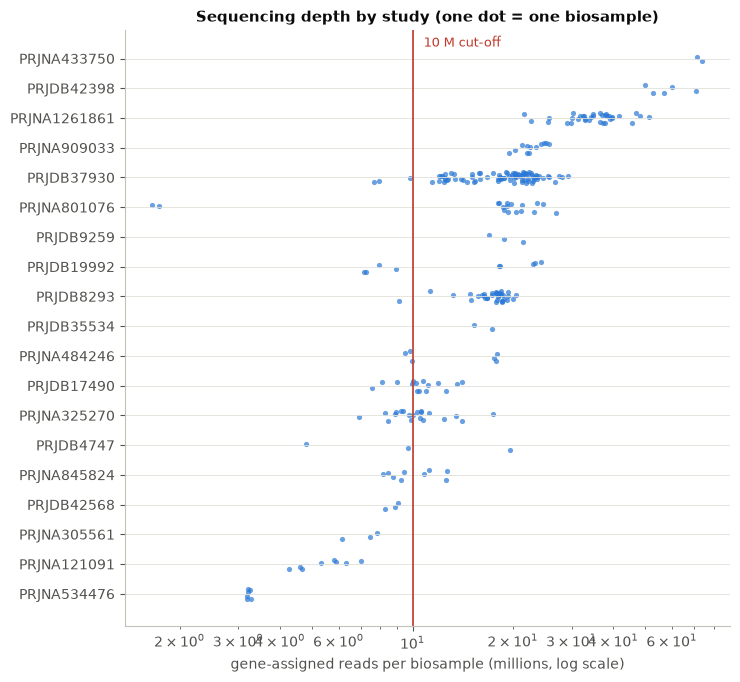

> **Live scope.** 279 biosamples (19 studies, 18 strains); 0 with unknown depth. Median depth 18.3 M assigned reads.

In [2]:
con = duckdb.connect(str(DATABASE_FILE), read_only=True)
units = fetch_biosample_units(con)
units["strain"] = units["strain"].fillna("unknown")
tpm_all = collapse_to_biosamples(fetch_gene_sample_tpm(con), units)                 # genes x biosamples, raw TPM
unit_meta = units.drop_duplicates("unit_id").set_index("unit_id").reindex(tpm_all.columns)[["bioproject", "strain"]]
depth = fetch_biosample_depth(con, units).reindex(tpm_all.columns)
genes_tbl = con.execute('SELECT canonical_gene_id, gene_symbol, description, chromosome, start, "end" FROM genes').fetchdf().set_index("canonical_gene_id")
go = load_go_annotations(FUNGIDB_GO_GAF_FILE)
onto = load_go_obo(GO_OBO_FILE) if GO_OBO_FILE.is_file() else None

selected = select_biosamples(depth, PARAMS.min_assigned_reads)
cutoff_table = depth_scope_table(depth, unit_meta, cutoffs_millions=(0, 1, 2, 5, 10, 15, 20, 30, 50))
display(cutoff_table)

per_study = pd.DataFrame({
    "biosamples": unit_meta.groupby("bioproject").size(),
    "retained": unit_meta.loc[selected].groupby("bioproject").size(),
    "median_Mreads": depth.groupby(unit_meta["bioproject"]).median() / 1e6,
}).fillna({"retained": 0}).astype({"retained": int}).sort_values("median_Mreads")
per_strain = pd.DataFrame({
    "biosamples": unit_meta.groupby("strain").size(),
    "retained": unit_meta.loc[selected].groupby("strain").size(),
}).fillna({"retained": 0}).astype({"retained": int})

fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(per_study) + 1.6))
for y, study in enumerate(per_study.index):
    vals = depth[unit_meta["bioproject"] == study].dropna() / 1e6
    ax.scatter(vals, np.full(len(vals), y) + np.random.default_rng(0).uniform(-0.18, 0.18, len(vals)), s=14, color="#2a78d6", alpha=0.7, linewidths=0)
ax.axvline(PARAMS.min_assigned_reads / 1e6, color="#c0392b", lw=1.2)
ax.text(PARAMS.min_assigned_reads / 1e6 * 1.08, len(per_study) - 0.6, f"{PARAMS.min_assigned_reads / 1e6:g} M cut-off", color="#c0392b", fontsize=9)
ax.set_xscale("log"); ax.set_yticks(range(len(per_study))); ax.set_yticklabels(per_study.index)
ax.set_xlabel("gene-assigned reads per biosample (millions, log scale)")
ax.set_title("Sequencing depth by study (one dot = one biosample)")
fig.tight_layout(); save_fig(fig, "coexpr_depth_by_study.png"); plt.show()

lost = per_study.index[per_study["retained"] == 0].tolist()
thinned = per_study[(per_study["retained"] > 0) & (per_study["retained"] < per_study["biosamples"])]
n_tot, n_sel = len(depth), len(selected)
display(Markdown(
    f"> **Live scope.** {n_tot} biosamples ({unit_meta['bioproject'].nunique()} studies, {unit_meta['strain'].nunique()} strains); "
    f"{int(depth.isna().sum())} with unknown depth. Median depth {depth.median() / 1e6:.1f} M assigned reads."
))


In [3]:
display(Markdown(
    f"**Answer.** At {PARAMS.min_assigned_reads / 1e6:g} M assigned reads **{n_sel} of {n_tot} biosamples ({pct(n_sel / n_tot)})** remain, "
    f"from {unit_meta.loc[selected, 'bioproject'].nunique()} of {unit_meta['bioproject'].nunique()} studies and "
    f"{unit_meta.loc[selected, 'strain'].nunique()} of {unit_meta['strain'].nunique()} strains. "
    + (f"Studies lost completely: {', '.join(lost)}. " if lost else "No study is lost completely. ")
    + (f"{len(thinned)} more studies lose part of their biosamples (largest loss: {(thinned['biosamples'] - thinned['retained']).idxmax()}, "
       f"{int((thinned['biosamples'] - thinned['retained']).max())} biosamples). " if len(thinned) else "")
    + "Strains lost completely: " + (", ".join(s[:36] + ("..." if len(s) > 36 else "") for s in per_strain.index[per_strain["retained"] == 0]) or "none") + "."
))


**Answer.** At 10 M assigned reads **226 of 279 biosamples (81%)** remain, from 15 of 19 studies and 12 of 18 strains. Studies lost completely: PRJNA534476, PRJNA121091, PRJNA305561, PRJDB42568. 9 more studies lose part of their biosamples (largest loss: PRJNA325270, 9 biosamples). Strains lost completely: RIB915, TK-35, TK-41, The A. oryzae strain HacA-CA, a hacA..., The A. oryzae strain HacA-DE, a hacA..., The A. oryzae strain niaD300, a niaD....

**Conclusion.** The cut-off is a trade between per-sample quality and breadth: correlations from shallow
libraries are noisier (low counts inflate the relative noise of log-TPM), but every study or strain it removes
is a part of the condition space the network can no longer see. The decision is therefore not made on
principle — Section 2 measures what a deeper filter buys in recovery of known functional groups.


## 2. Does the depth cut-off improve the network?

**Question.** Does requiring more assigned reads recover known functional groups better, or does it only
discard samples?

*Benchmark (same idea AFED used to compare workflows).* For each curated functional group (ribosome/translation,
proteasome, central metabolism, stress, secreted enzymes, secondary metabolism, cytoskeleton/chromatin; GO terms +
product keywords) we ask: **AUC = P(r of a random same-group pair > r of a random gene pair)**. 0.5 = the group is
not co-expressed more than chance. These are crude sets — an AUC near 0.5 can mean the group is genuinely
heterogeneous, not that the method fails — so the benchmark is a relative yardstick between workflows.


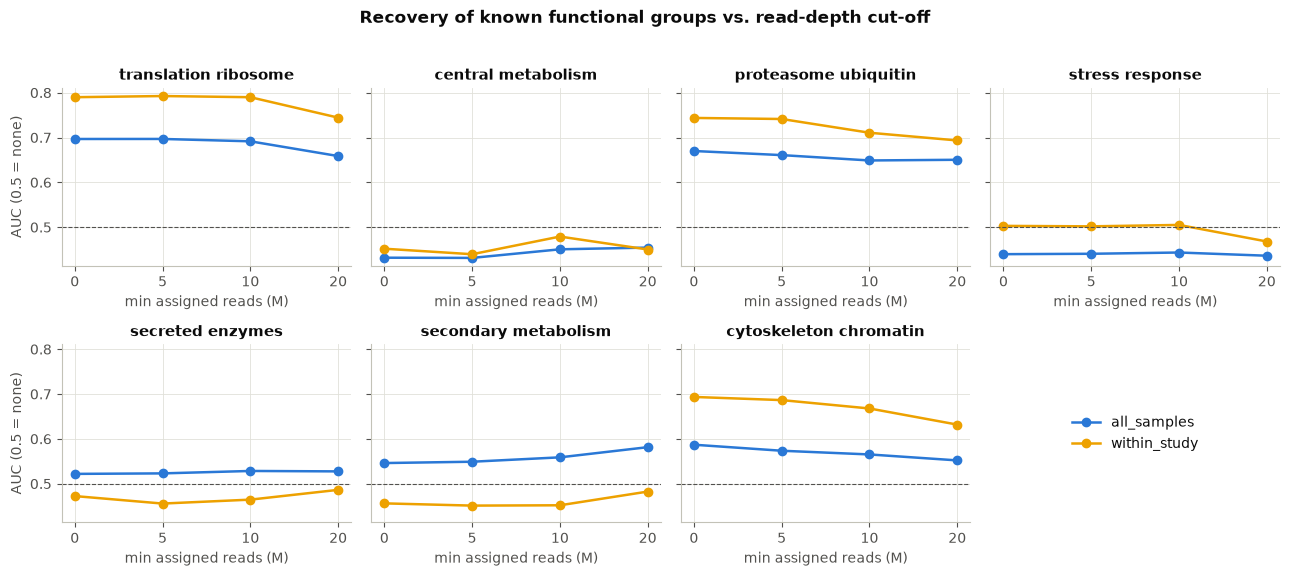

,cutoff_M,mode,biosamples,studies,genes_in_network,bg_abs_r_ge_0_5
0,0,all_samples,279,19,10291,0.152
1,0,within_study,275,17,10291,0.067
2,5,all_samples,267,18,10242,0.156
3,5,within_study,261,15,10242,0.072
4,10,all_samples,226,15,10111,0.161
5,10,within_study,221,12,10111,0.066
6,20,all_samples,106,9,9894,0.202
7,20,within_study,102,6,9894,0.112


mode                   all_samples                      within_study         \
cutoff_M                        0      5      10     20           0      5    
group                                                                         
central_metabolism           0.432  0.431  0.451  0.455        0.452  0.440   
cytoskeleton_chromatin       0.587  0.573  0.565  0.552        0.693  0.686   
proteasome_ubiquitin         0.670  0.661  0.649  0.650        0.744  0.741   
secondary_metabolism         0.546  0.549  0.559  0.581        0.456  0.451   
secreted_enzymes             0.522  0.523  0.528  0.527        0.472  0.456   
stress_response              0.440  0.441  0.444  0.436        0.503  0.502   
translation_ribosome         0.697  0.697  0.692  0.659        0.790  0.793   

mode                                  
cutoff_M                   10     20  
group                                 
central_metabolism      0.479  0.450  
cytoskeleton_chromatin  0.668  0.632  
proteasome_ubiquitin    0.711  0.693  
secondary_metabolism    0.452  0.482  
secreted_enzymes        0.464  0.486  
stress_response         0.505  0.468  
translation_ribosome    0.790  0.744

In [4]:
def benchmark_run(cut_m, method="spearman", seed=0):
    params = CoexprParams(min_assigned_reads=cut_m * 1e6, method=method)
    sel = select_biosamples(depth, params.min_assigned_reads)
    tpm_sel = tpm_all[sel]
    genes = tpm_sel.index[(tpm_sel.mean(axis=1) >= params.min_mean_tpm).to_numpy()]
    sets = build_gene_sets(go, genes_tbl["description"], genes)
    study_sel = unit_meta.loc[sel, "bioproject"]
    rows = []
    for mode in MODES:
        prepared = prepare_expression(tpm_sel, study_sel, mode, params, genes=genes)
        null = correlation_null(prepared.z, params.null_pairs, seed)
        bench = functional_benchmark(prepared.z, prepared.genes, sets, null, seed=seed)
        bench = bench.assign(mode=mode, cutoff_M=cut_m, method=method, biosamples=prepared.n_samples, studies=prepared.n_studies,
                             genes_in_network=len(genes), bg_abs_r_ge_0_5=(np.abs(null) >= 0.5).mean())
        rows.append(bench)
    return pd.concat(rows, ignore_index=True)


CUTOFFS = (0, 5, 10, 20)
by_cutoff = pd.concat([benchmark_run(c) for c in CUTOFFS], ignore_index=True)
groups = list(dict.fromkeys(by_cutoff["group"]))

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
axes = axes.ravel()
for ax, group in zip(axes, groups):
    for mode in MODES:
        d = by_cutoff[(by_cutoff["group"] == group) & (by_cutoff["mode"] == mode)].sort_values("cutoff_M")
        ax.plot(range(len(d)), d["auc"], marker="o", color=MODE_COLORS[mode], lw=1.8, label=mode)
        ax.set_xticks(range(len(d))); ax.set_xticklabels([f"{c:g}" for c in d["cutoff_M"]])
    ax.axhline(0.5, color=MUTED, lw=0.8, ls="--")
    ax.set_title(group.replace("_", " "))
    ax.set_xlabel("min assigned reads (M)")
axes[0].set_ylabel("AUC (0.5 = none)")
axes[4].set_ylabel("AUC (0.5 = none)")
for ax in axes[len(groups):]:
    ax.axis("off")
axes[len(groups)].legend(*axes[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=10) if len(groups) < len(axes) else None
fig.suptitle("Recovery of known functional groups vs. read-depth cut-off", y=1.02, fontsize=12, fontweight="bold")
fig.tight_layout(); save_fig(fig, "coexpr_cutoff_benchmark.png"); plt.show()

scope_by_cutoff = by_cutoff.drop_duplicates(["cutoff_M", "mode"])[["cutoff_M", "mode", "biosamples", "studies", "genes_in_network", "bg_abs_r_ge_0_5"]]
display(scope_by_cutoff.round(3).reset_index(drop=True))
display(by_cutoff.pivot_table(index=["group"], columns=["mode", "cutoff_M"], values="auc").round(3))


In [5]:
auc = by_cutoff.pivot_table(index=["mode", "group"], columns="cutoff_M", values="auc")
mean_auc = auc.groupby("mode").mean()
base, chosen, deep = 0, int(PARAMS.min_assigned_reads / 1e6), max(CUTOFFS)
sizes = scope_by_cutoff.set_index(["mode", "cutoff_M"])["biosamples"]
display(Markdown(
    "**Answer.** Mean AUC over the benchmark groups by cut-off (M assigned reads): "
    + "; ".join(f"**{m}**: " + ", ".join(f"{c:g} M -> {mean_auc.loc[m, c]:.3f} ({sizes[(m, c)]} biosamples)" for c in CUTOFFS) for m in MODES)
    + f". Going from no filter to {chosen} M changes the mean AUC by "
    + ", ".join(f"{mean_auc.loc[m, chosen] - mean_auc.loc[m, base]:+.3f} ({m})" for m in MODES)
    + f"; going on to {deep} M by "
    + ", ".join(f"{mean_auc.loc[m, deep] - mean_auc.loc[m, chosen]:+.3f} ({m})" for m in MODES) + "."
))


**Answer.** Mean AUC over the benchmark groups by cut-off (M assigned reads): **all_samples**: 0 M -> 0.556 (279 biosamples), 5 M -> 0.554 (267 biosamples), 10 M -> 0.555 (226 biosamples), 20 M -> 0.552 (106 biosamples); **within_study**: 0 M -> 0.587 (275 biosamples), 5 M -> 0.581 (261 biosamples), 10 M -> 0.581 (221 biosamples), 20 M -> 0.565 (102 biosamples). Going from no filter to 10 M changes the mean AUC by -0.001 (all_samples), -0.006 (within_study); going on to 20 M by -0.004 (all_samples), -0.016 (within_study).

In [6]:
max_cut_effect = (auc[chosen] - auc[base]).abs().max()
mode_gap = (auc[chosen].unstack("mode")["within_study"] - auc[chosen].unstack("mode")["all_samples"]).abs()
display(Markdown(
    f"**Conclusion.** In this benchmark the depth filter does **not** improve recovery: no group moves by more than {max_cut_effect:.3f} AUC between "
    f"no filter and {chosen} M (mean change {mean_auc.loc[:, chosen].sub(mean_auc.loc[:, base]).mean():+.3f}), while the two modes differ by up to "
    f"{mode_gap.max():.2f} within the same group at {chosen} M (largest for **{mode_gap.idxmax()}**). Deeper cut-offs mainly cost biosamples "
    f"({n_tot - n_sel} here at {chosen} M). Two cautions: the benchmark groups (ribosome, proteasome...) are made of highly expressed genes, which "
    f"are insensitive to depth, so the benchmark has little power to see what a depth filter protects — the noise of *lowly* expressed genes; and "
    f"there are only seven crude groups and no uncertainty interval. {chosen} M is therefore kept as AFED's conservative default, exposed as a "
    f"parameter (`--min-reads-millions`, 0 disables it), and the real lever is the choice of mode (Sections 3-4)."
))


**Conclusion.** In this benchmark the depth filter does **not** improve recovery: no group moves by more than 0.033 AUC between no filter and 10 M (mean change -0.003), while the two modes differ by up to 0.11 within the same group at 10 M (largest for **secondary_metabolism**). Deeper cut-offs mainly cost biosamples (53 here at 10 M). Two cautions: the benchmark groups (ribosome, proteasome...) are made of highly expressed genes, which are insensitive to depth, so the benchmark has little power to see what a depth filter protects — the noise of *lowly* expressed genes; and there are only seven crude groups and no uncertainty interval. 10 M is therefore kept as AFED's conservative default, exposed as a parameter (`--min-reads-millions`, 0 disables it), and the real lever is the choice of mode (Sections 3-4).

## 3. How much of the pooled correlation is study structure?

**Question.** AFED applied no batch correction and a fixed r ≥ 0.5. In an atlas assembled from many studies
and strains, how much of the correlation between *unrelated* genes comes from between-study differences?

*Two views.* (a) **Random gene pairs:** the distribution of r and the share passing |r| ≥ 0.5 in each mode —
random pairs should essentially never pass a meaningful cut-off. (b) **Variance by study/strain:** η² per gene
= share of the variance of log2(TPM+1) lying *between* studies (or strains).


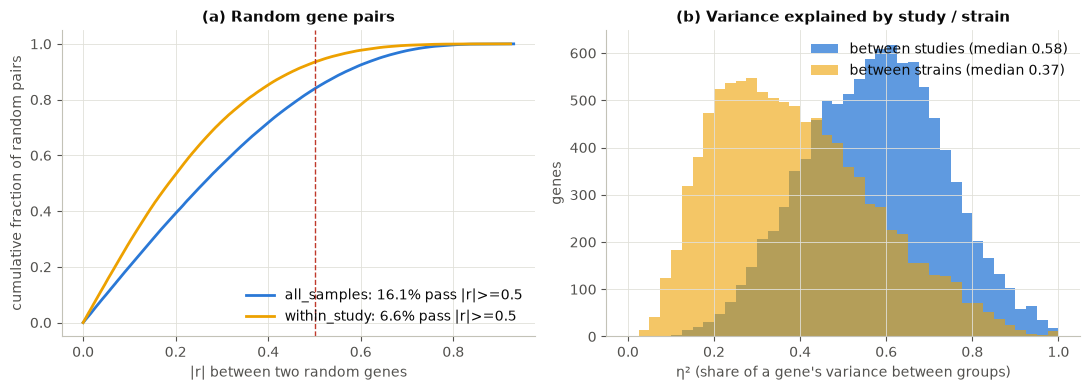

,n_pairs,mean_r,q50_r,q99_r,fraction_abs_r_ge_0.5,fraction_r_ge_0.5
all_samples,199986.0,0.165,0.180,0.752,0.161,0.146
within_study,199983.0,0.140,0.135,0.660,0.066,0.064


In [7]:
tpm_sel = tpm_all[selected]
net_genes = tpm_sel.index[(tpm_sel.mean(axis=1) >= PARAMS.min_mean_tpm).to_numpy()]
study_sel = unit_meta.loc[selected, "bioproject"]
strain_sel = unit_meta.loc[selected, "strain"]
prep = {m: prepare_expression(tpm_sel, study_sel, m, PARAMS, genes=net_genes) for m in MODES}
nulls = {m: correlation_null(prep[m].z, PARAMS.null_pairs, i) for i, m in enumerate(MODES)}
null_stats = pd.DataFrame({m: null_summary(nulls[m]) for m in MODES}).T


def eta_squared(log_expr, groups):
    '''Per-gene share of the variance lying between groups (between-group SS / total SS).'''
    total = ((log_expr - log_expr.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    between = np.zeros(log_expr.shape[0])
    grand = log_expr.mean(axis=1)
    for g in np.unique(groups):
        cols = groups == g
        between += cols.sum() * (log_expr[:, cols].mean(axis=1) - grand) ** 2
    return np.divide(between, total, out=np.zeros_like(between), where=total > 0)


log_all = prep["all_samples"].log_expr
eta_study = eta_squared(log_all, study_sel.to_numpy())
eta_strain = eta_squared(log_all, strain_sel.to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m in MODES:
    xs = np.sort(np.abs(nulls[m]))
    axes[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=MODE_COLORS[m], lw=2, label=f"{m}: {pct(null_stats.loc[m, 'fraction_abs_r_ge_0.5'], 1)} pass |r|>=0.5")
axes[0].axvline(0.5, color="#c0392b", lw=1, ls="--")
axes[0].set_xlabel("|r| between two random genes"); axes[0].set_ylabel("cumulative fraction of random pairs")
axes[0].set_title("(a) Random gene pairs"); axes[0].legend(frameon=False, loc="lower right")
axes[1].hist(eta_study, bins=40, range=(0, 1), color="#2a78d6", alpha=0.75, label=f"between studies (median {np.median(eta_study):.2f})")
axes[1].hist(eta_strain, bins=40, range=(0, 1), color="#eda100", alpha=0.6, label=f"between strains (median {np.median(eta_strain):.2f})")
axes[1].set_xlabel("η² (share of a gene's variance between groups)"); axes[1].set_ylabel("genes")
axes[1].set_title("(b) Variance explained by study / strain"); axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout(); save_fig(fig, "coexpr_structure.png"); plt.show()
display(null_stats.round(3))


In [8]:
display(Markdown(
    f"**Answer.** Among random gene pairs, **{pct(null_stats.loc['all_samples', 'fraction_abs_r_ge_0.5'], 1)}** exceed |r| >= 0.5 in `all_samples` "
    f"versus **{pct(null_stats.loc['within_study', 'fraction_abs_r_ge_0.5'], 1)}** in `within_study`; the median random pair has "
    f"r = {null_stats.loc['all_samples', 'q50_r']:+.2f} / {null_stats.loc['within_study', 'q50_r']:+.2f}. "
    f"The typical gene has {pct(np.median(eta_study))} of its variance between studies and {pct(np.median(eta_strain))} between strains "
    f"(strain and study are partly the same thing: several strains occur in a single study)."
))


**Answer.** Among random gene pairs, **16.1%** exceed |r| >= 0.5 in `all_samples` versus **6.6%** in `within_study`; the median random pair has r = +0.18 / +0.14. The typical gene has 58% of its variance between studies and 37% between strains (strain and study are partly the same thing: several strains occur in a single study).

**Conclusion.** A fixed r cut-off does not mean the same thing in the two modes: the same r = 0.5 admits a
very different share of *random* pairs, so a threshold tuned on one atlas does not transfer to the next (or to
the same atlas after more studies are added). That is why the network is defined by **ranks** — each gene's
best neighbours, mutual rank and the tail of r against random pairs (`bg_tail`) — and why the within-study mode
exists. Centering per study cannot remove biology that truly varies between studies, which Section 4 shows is
a real cost for some gene groups.


## 4. Which correlation, and which mode?

**Question.** Pearson or Spearman, pooled or within-study — which recovers the benchmark groups best, and does
the answer depend on the group?


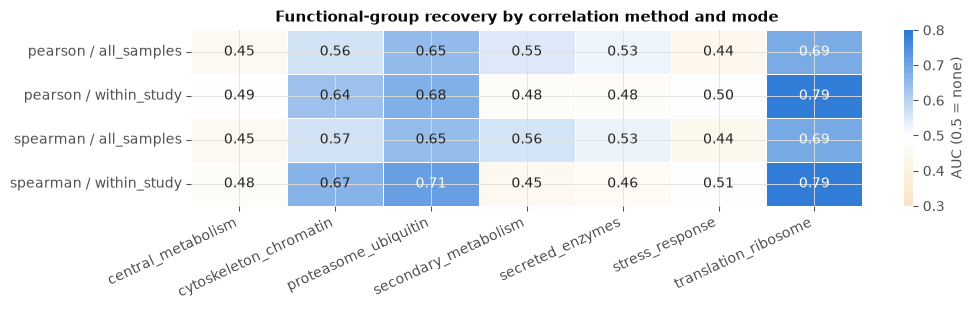

,random pairs |r|>=0.5
variant,
pearson / all_samples,0.132
pearson / within_study,0.062
spearman / all_samples,0.161
spearman / within_study,0.066


In [9]:
variants = pd.concat([benchmark_run(PARAMS.min_assigned_reads / 1e6, method=m) for m in ("pearson", "spearman")], ignore_index=True)
variants["variant"] = variants["method"] + " / " + variants["mode"]
grid = variants.pivot_table(index="variant", columns="group", values="auc")
bg = variants.drop_duplicates("variant").set_index("variant")["bg_abs_r_ge_0_5"].reindex(grid.index)

fig, ax = plt.subplots(figsize=(10.5, 3.2))
sns.heatmap(grid, annot=True, fmt=".2f", cmap=sns.blend_palette(["#f3d9a4", "#ffffff", "#2a78d6"], as_cmap=True), center=0.5, vmin=0.3, vmax=0.8,
            cbar_kws={"label": "AUC (0.5 = none)"}, linewidths=0.5, linecolor="white", ax=ax)
ax.set_ylabel(""); ax.set_xlabel(""); ax.set_title("Functional-group recovery by correlation method and mode")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout(); save_fig(fig, "coexpr_method_mode.png"); plt.show()
display(pd.DataFrame({"random pairs |r|>=0.5": bg.round(3)}))


In [10]:
spear = variants[variants["method"] == "spearman"].pivot_table(index="group", columns="mode", values="auc")
pear = variants[variants["method"] == "pearson"].pivot_table(index="group", columns="mode", values="auc")
favours_within = spear.index[(spear["within_study"] - spear["all_samples"]) > 0.03].tolist()
favours_all = spear.index[(spear["all_samples"] - spear["within_study"]) > 0.03].tolist()
method_gap = (spear - pear).abs().stack().max()
display(Markdown(
    f"**Answer.** Spearman minus Pearson changes AUC by at most {method_gap:.3f} in any group/mode cell. "
    f"Within-study centering is better by more than 0.03 AUC for: **{', '.join(favours_within) or 'no group'}**; pooled (`all_samples`) is better for: "
    f"**{', '.join(favours_all) or 'no group'}**; the remaining groups differ by less than 0.03. "
    f"Groups whose AUC never reaches 0.6 in any variant: "
    f"{', '.join(variants.groupby('group')['auc'].max().loc[lambda s: s < 0.6].index) or 'none'}; "
    f"of these, members correlate *less* than random gene pairs (AUC < 0.5) in every variant for: "
    f"{', '.join(variants.groupby('group')['auc'].max().loc[lambda s: s < 0.5].index) or 'none'}."
))


**Answer.** Spearman minus Pearson changes AUC by at most 0.036 in any group/mode cell. Within-study centering is better by more than 0.03 AUC for: **cytoskeleton_chromatin, proteasome_ubiquitin, stress_response, translation_ribosome**; pooled (`all_samples`) is better for: **secondary_metabolism, secreted_enzymes**; the remaining groups differ by less than 0.03. Groups whose AUC never reaches 0.6 in any variant: central_metabolism, secondary_metabolism, secreted_enzymes, stress_response; of these, members correlate *less* than random gene pairs (AUC < 0.5) in every variant for: central_metabolism.

**Conclusion.** Spearman is kept as the default (it is invariant to the monotone transforms TPM goes through
and is robust to the heavy tails of expression), but the choice between Pearson and Spearman is not what
matters here. The mode is: housekeeping-type machinery (ribosome, proteasome, cytoskeleton/chromatin) gains from
centering, consistent with its co-variation happening *inside* studies, while the groups that lose signal when
each study is centered (secondary metabolism, secreted enzymes) are consistent with co-variation **between**
studies/strains — an interpretation, not something this benchmark can prove. An AUC below 0.5 does not mean
"anti-correlated genes": those groups are heterogeneous (members from many unrelated clusters) while random pairs
share the atlas-wide positive background. Neither mode dominates, so the pipeline builds **both** and the network
view lets the user choose or combine them.


## 5. The neighbour lists

**Question.** Using the library pipeline (`build_coexpression`, identical to `atlas coexpr build`), how strong
are the top-N neighbours relative to the random-pair background, and how much do the two modes agree on who a
gene's neighbours are?


> **Live scope.** 10,111 genes in the network; 226 biosamples from 15 studies, 12 strains. Modes built: all_samples, within_study.

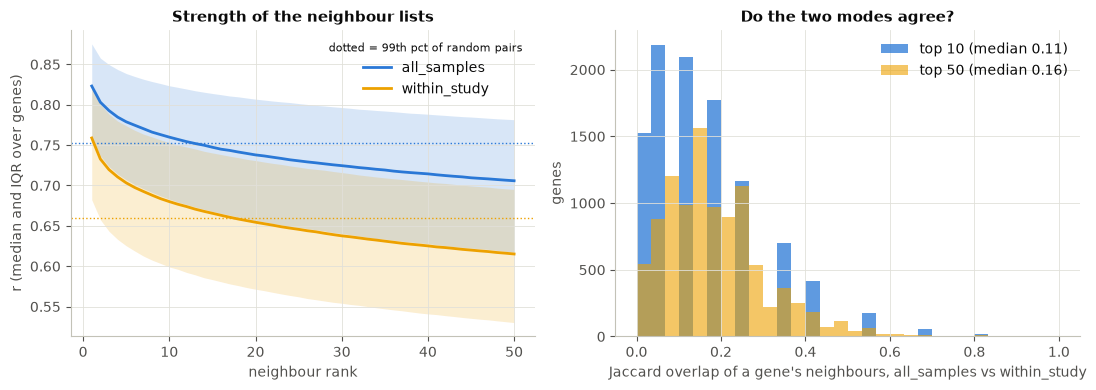

,all_samples,within_study
median r of best neighbour,0.823,0.759
median r of rank 50,0.706,0.615
genes with a neighbour at mutual rank <= 2,0.508,0.525


,mode,neighbour ranks,median r,edges above random-pair P99,edges above P99.9
0,all_samples,1,0.823,0.772,0.441
1,all_samples,2-5,0.790,0.649,0.297
2,all_samples,6-10,0.767,0.556,0.219
3,all_samples,11-25,0.742,0.465,0.155
4,all_samples,26-50,0.717,0.378,0.097
5,within_study,1,0.759,0.805,0.418
6,within_study,2-5,0.717,0.694,0.273
7,within_study,6-10,0.689,0.601,0.197
8,within_study,11-25,0.660,0.500,0.135
9,within_study,26-50,0.628,0.395,0.087


In [11]:
result = build_coexpression(con, PARAMS, gaf_path=FUNGIDB_GO_GAF_FILE, obo_path=GO_OBO_FILE)
scope = result.scope
nb = {m: result.modes[m].neighbours for m in result.modes}
display(Markdown(
    f"> **Live scope.** {scope['n_genes']:,} genes in the network; {scope['n_biosamples_selected']} biosamples from {scope['n_studies_selected']} studies, "
    f"{scope['n_strains_selected']} strains. Modes built: {', '.join(result.modes)}."
    + (f" Skipped: {scope['skipped_modes']}." if scope["skipped_modes"] else "")
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m in nb:
    wide = nb[m].pivot(index="gene_id", columns="rank", values="r")
    med, q25, q75 = wide.median(), wide.quantile(0.25), wide.quantile(0.75)
    axes[0].plot(med.index, med, color=MODE_COLORS[m], lw=2, label=m)
    axes[0].fill_between(med.index, q25, q75, color=MODE_COLORS[m], alpha=0.18, linewidth=0)
    axes[0].axhline(result.modes[m].null["q99_r"], color=MODE_COLORS[m], lw=1, ls=":")
axes[0].set_xlabel("neighbour rank"); axes[0].set_ylabel("r (median and IQR over genes)")
axes[0].set_title("Strength of the neighbour lists"); axes[0].legend(frameon=False, title="dotted = 99th pct of random pairs", title_fontsize=8)

top10 = {m: nb[m][nb[m]["rank"] <= 10].groupby("gene_id")["neighbour_id"].agg(set) for m in nb}
top50 = {m: nb[m].groupby("gene_id")["neighbour_id"].agg(set) for m in nb}
if len(nb) == 2:
    a, b = list(nb)
    jac10 = pd.Series({g: len(top10[a][g] & top10[b][g]) / len(top10[a][g] | top10[b][g]) for g in top10[a].index})
    jac50 = pd.Series({g: len(top50[a][g] & top50[b][g]) / len(top50[a][g] | top50[b][g]) for g in top50[a].index})
    axes[1].hist(jac10, bins=30, range=(0, 1), color="#2a78d6", alpha=0.75, label=f"top 10 (median {jac10.median():.2f})")
    axes[1].hist(jac50, bins=30, range=(0, 1), color="#eda100", alpha=0.6, label=f"top {PARAMS.top_n} (median {jac50.median():.2f})")
    axes[1].set_xlabel("Jaccard overlap of a gene's neighbours, all_samples vs within_study"); axes[1].set_ylabel("genes"); axes[1].legend(frameon=False)
    axes[1].set_title("Do the two modes agree?")
fig.tight_layout(); save_fig(fig, "coexpr_neighbour_lists.png"); plt.show()

summary = pd.DataFrame({
    m: {
        "median r of best neighbour": nb[m][nb[m]["rank"] == 1]["r"].median(),
        f"median r of rank {PARAMS.top_n}": nb[m][nb[m]["rank"] == nb[m]["rank"].max()]["r"].median(),
        f"genes with a neighbour at mutual rank <= {MR_CUT}": (nb[m].groupby("gene_id")["mutual_rank"].min() <= MR_CUT).mean(),
    } for m in nb
}).round(3)
display(summary)

# How far above the random-pair background are the edges, by neighbour rank? (bg_tail = share of random pairs with r >= the edge's r)
rank_bins = [(1, 1), (2, 5), (6, 10), (11, 25), (26, PARAMS.top_n)]
tail_rows = []
for m in nb:
    for lo, hi in rank_bins:
        d = nb[m][(nb[m]["rank"] >= lo) & (nb[m]["rank"] <= hi)]
        tail_rows.append({
            "mode": m, "neighbour ranks": f"{lo}" if lo == hi else f"{lo}-{hi}", "median r": d["r"].median(),
            "edges above random-pair P99": (d["bg_tail"] <= 0.01).mean(), "edges above P99.9": (d["bg_tail"] <= 0.001).mean(),
        })
tail_table = pd.DataFrame(tail_rows)
display(tail_table.round(3))

# Do the modes agree on FUNCTION even when they list different neighbours?
enrichment_all = result.enrichment()
shared_function = np.nan
if len(enrichment_all) and len(nb) == 2:
    sig = {m: enrichment_all[enrichment_all["mode"] == m].groupby("gene_id")["term"].agg(set) for m in nb}
    both = sig[a].index.intersection(sig[b].index)
    shared_function = float(np.mean([len(sig[a][g] & sig[b][g]) > 0 for g in both])) if len(both) else np.nan


In [12]:
parts = []
for m in nb:
    parts.append(
        f"`{m}`: best-neighbour r median {summary.loc['median r of best neighbour', m]:.2f}, rank-{PARAMS.top_n} neighbour "
        f"{summary.loc[f'median r of rank {PARAMS.top_n}', m]:.2f} (random-pair 99th percentile {result.modes[m].null['q99_r']:.2f}); "
        f"{pct(summary.loc[f'genes with a neighbour at mutual rank <= {MR_CUT}', m])} of genes have a neighbour at mutual rank <= {MR_CUT}"
    )
agree = (f" The modes share a median {jac10.median():.0%} of a gene's top 10 neighbours and {jac50.median():.0%} of its top {PARAMS.top_n}"
         + (f"; among genes with a significant GO term in both modes, {pct(shared_function)} share at least one term." if np.isfinite(shared_function) else ".") if len(nb) == 2 else "")
top1 = tail_table[tail_table["neighbour ranks"] == "1"].set_index("mode")["edges above random-pair P99"]
deep = tail_table[tail_table["neighbour ranks"] == f"{rank_bins[-1][0]}-{rank_bins[-1][1]}"].set_index("mode")["edges above random-pair P99"]
tails = " Share of edges above the 99th percentile of random pairs, best neighbour vs. ranks " + f"{rank_bins[-1][0]}-{rank_bins[-1][1]}: " + "; ".join(f"`{m}` {pct(top1[m])} vs {pct(deep[m])}" for m in nb) + "."
display(Markdown("**Answer.** " + "; ".join(parts) + "." + tails + agree))


**Answer.** `all_samples`: best-neighbour r median 0.82, rank-50 neighbour 0.71 (random-pair 99th percentile 0.75); 51% of genes have a neighbour at mutual rank <= 2; `within_study`: best-neighbour r median 0.76, rank-50 neighbour 0.61 (random-pair 99th percentile 0.66); 52% of genes have a neighbour at mutual rank <= 2. Share of edges above the 99th percentile of random pairs, best neighbour vs. ranks 26-50: `all_samples` 77% vs 38%; `within_study` 80% vs 40%. The modes share a median 11% of a gene's top 10 neighbours and 16% of its top 50; among genes with a significant GO term in both modes, 81% share at least one term.

In [13]:
per_mode_gap = "; ".join(
    f"`{m}`: median rank-{PARAMS.top_n} r {summary.loc[f'median r of rank {PARAMS.top_n}', m]:.2f} vs random-pair P99 {result.modes[m].null['q99_r']:.2f}" for m in nb)
frac_ge = "/".join(pct(result.modes[m].null["fraction_r_ge_0.5"], 1) for m in nb)
display(Markdown(
    "**Conclusion.** The best neighbours typically stand above the random-pair background, but r alone is a weak criterion in this atlas: "
    f"the median rank-{PARAMS.top_n} neighbour sits at or below the 99th percentile of random pairs ({per_mode_gap}), strength decays smoothly with rank, "
    f"and a fixed r >= 0.5 (AFED's cut-off) is reached by {frac_ge} of *random* gene pairs ({', '.join(nb)}), i.e. it would admit mostly background here. "
    "What carries the information is the **rank** of a neighbour within a gene's list and the **mutual rank** (close from both sides), which is what the edges "
    "are cut on (Section 9). "
    + (
        "The two modes list largely different neighbours; "
        + (f"{pct(shared_function)} of the genes enriched in both modes share at least one GO term (an upper bound: ancestor propagation makes related terms overlap)" if np.isfinite(shared_function) else "their functional agreement could not be measured")
        + (" — they disagree more on *which* members of a functional neighbourhood come first than on the function itself." if np.isfinite(shared_function) and shared_function >= 0.5
           else " — so the modes are not just two orderings of the same neighbourhood, they often point to different functions and should both be read." if np.isfinite(shared_function) else ".")
        if len(nb) == 2 else ""
    )
))


**Conclusion.** The best neighbours typically stand above the random-pair background, but r alone is a weak criterion in this atlas: the median rank-50 neighbour sits at or below the 99th percentile of random pairs (`all_samples`: median rank-50 r 0.71 vs random-pair P99 0.75; `within_study`: median rank-50 r 0.61 vs random-pair P99 0.66), strength decays smoothly with rank, and a fixed r >= 0.5 (AFED's cut-off) is reached by 14.6%/6.4% of *random* gene pairs (all_samples, within_study), i.e. it would admit mostly background here. What carries the information is the **rank** of a neighbour within a gene's list and the **mutual rank** (close from both sides), which is what the edges are cut on (Section 9). The two modes list largely different neighbours; 81% of the genes enriched in both modes share at least one GO term (an upper bound: ancestor propagation makes related terms overlap) — they disagree more on *which* members of a functional neighbourhood come first than on the function itself.

## 6. Are the edges supported inside individual studies?

**Question.** For an edge that looks strong in the pooled data, does the correlation also hold *inside* single
studies — or is it carried by differences between studies? Every edge carries `within_study_median_r`: the
median over studies (≥ 3 biosamples, both genes variable) of the correlation computed within that study alone.


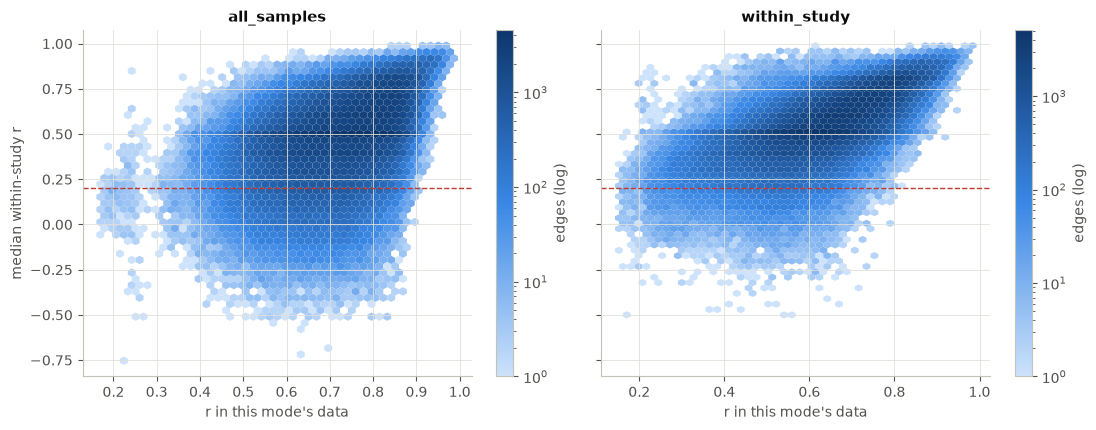

,mr_bin,mode,edges,median within-study r,share with support < 0.2,share testable in no study
0,MR <= 5,all_samples,25154,0.626,0.027,0.0
1,5 < MR <= 10,all_samples,32528,0.581,0.044,0.0
2,10 < MR <= 25,all_samples,91549,0.545,0.058,0.0
3,MR > 25,all_samples,356319,0.495,0.112,0.0
4,MR <= 5,within_study,25618,0.695,0.005,0.0
5,5 < MR <= 10,within_study,33246,0.645,0.007,0.0
6,10 < MR <= 25,within_study,94663,0.609,0.013,0.0
7,MR > 25,within_study,352023,0.532,0.031,0.0


,random pairs: median within-study r,random pairs: share < 0.2
all_samples,0.155,0.565
within_study,0.150,0.569


In [14]:
fig, axes = plt.subplots(1, len(nb), figsize=(5.6 * len(nb), 4.4), sharey=True, squeeze=False)
for ax, m in zip(axes[0], nb):
    d = nb[m].dropna(subset=["within_study_median_r"])
    hb = ax.hexbin(d["r"], d["within_study_median_r"], gridsize=45, cmap=sns.blend_palette(BLUE_RAMP, as_cmap=True), mincnt=1, bins="log", linewidths=0)
    ax.axhline(SUPPORT_MIN, color="#c0392b", lw=1, ls="--")
    ax.set_xlabel("r in this mode's data"); ax.set_title(m)
    fig.colorbar(hb, ax=ax, label="edges (log)")
axes[0][0].set_ylabel("median within-study r")
fig.tight_layout(); save_fig(fig, "coexpr_edge_support.png"); plt.show()

bins = [0, 5, 10, 25, np.inf]
labels = ["MR <= 5", "5 < MR <= 10", "10 < MR <= 25", "MR > 25"]
rows = []
for m in nb:
    d = nb[m].assign(mr_bin=pd.cut(nb[m]["mutual_rank"], bins=bins, labels=labels))
    g = d.groupby("mr_bin", observed=True)
    rows.append(pd.DataFrame({
        "mode": m, "edges": g.size(),
        "median within-study r": g["within_study_median_r"].median(),
        f"share with support < {SUPPORT_MIN}": g["within_study_median_r"].apply(lambda s: (s < SUPPORT_MIN).mean()),
        "share testable in no study": g["n_studies_tested"].apply(lambda s: (s == 0).mean()),
    }).reset_index())
support_table = pd.concat(rows, ignore_index=True).round(3)
display(support_table)

# Baseline: how does the same statistic look for RANDOM gene pairs? (a check that it discriminates at all)
rng_b = np.random.default_rng(1)
baseline = {}
for m in nb:
    prepared = result.modes[m].prepared
    ri, rj = rng_b.integers(0, len(prepared.genes), 20_000), rng_b.integers(0, len(prepared.genes), 20_000)
    ok = ri != rj
    support_random, _ = study_consistency(prepared, ri[ok], rj[ok], PARAMS)
    baseline[m] = {"median": float(np.nanmedian(support_random)), "share_low": float((support_random < SUPPORT_MIN).mean())}
display(pd.DataFrame(baseline).T.rename(columns={"median": "random pairs: median within-study r", "share_low": f"random pairs: share < {SUPPORT_MIN}"}).round(3))


In [15]:
def share_unsupported(m, mr):
    d = nb[m][nb[m]["mutual_rank"] <= mr].dropna(subset=["within_study_median_r"])
    return (d["within_study_median_r"] < SUPPORT_MIN).mean(), len(d)


txt = []
for m in nb:
    frac, n = share_unsupported(m, MR_CUT)
    wide, n_wide = share_unsupported(m, 10 * MR_CUT)
    txt.append(
        f"in `{m}`, {pct(frac)} of the {n:,} edges with mutual rank <= {MR_CUT} (and {pct(wide)} of those <= {10 * MR_CUT}) have a median within-study r "
        f"below {SUPPORT_MIN}, against {pct(baseline[m]['share_low'])} of random gene pairs (median within-study r of random pairs: {baseline[m]['median']:+.2f})"
    )
display(Markdown("**Answer.** " + "; ".join(txt) + "."))


**Answer.** in `all_samples`, 2% of the 7,380 edges with mutual rank <= 2 (and 5% of those <= 20) have a median within-study r below 0.2, against 57% of random gene pairs (median within-study r of random pairs: +0.15); in `within_study`, 0% of the 7,700 edges with mutual rank <= 2 (and 1% of those <= 20) have a median within-study r below 0.2, against 57% of random gene pairs (median within-study r of random pairs: +0.15).

In [16]:
low_share = {m: share_unsupported(m, MR_CUT)[0] for m in nb}
display(Markdown(
    "**Conclusion.** The within-study median is an independent reliability check, and it discriminates: random pairs fail it far more often than "
    f"the top edges do. The strongest edges are therefore mostly **not** artefacts of between-study differences ({', '.join(f'{m}: only {pct(low_share[m], 1)} unsupported' for m in nb)} "
    f"at mutual rank <= {MR_CUT}) — the study structure that inflates the random-pair background (Section 3) does not drive the top of the lists. "
    "Support matters more for weaker edges (see the table), which is why it is a per-edge column the network view can filter on rather than a global exclusion. "
    "A low value cannot say whether an edge is a batch effect or biology that really differs between studies; it only says the relationship is not visible inside individual studies."
))


**Conclusion.** The within-study median is an independent reliability check, and it discriminates: random pairs fail it far more often than the top edges do. The strongest edges are therefore mostly **not** artefacts of between-study differences (all_samples: only 2.0% unsupported, within_study: only 0.4% unsupported at mutual rank <= 2) — the study structure that inflates the random-pair background (Section 3) does not drive the top of the lists. Support matters more for weaker edges (see the table), which is why it is a per-edge column the network view can filter on rather than a global exclusion. A low value cannot say whether an edge is a batch effect or biology that really differs between studies; it only says the relationship is not visible inside individual studies.

## 7. Examples: one gene and a gene set

**Question.** Do the neighbourhoods of well-understood genes look biologically sensible, and does the
gene-*set* query (AFED's "individual gene or set of genes") work?

*Genes.* A 60S ribosomal protein (expected: ribosome/translation neighbours), a glucoamylase and an
alpha-amylase (koji hydrolases — no expectation beyond what the data show), and a polyketide synthase
(secondary metabolism, often clustered in the genome).


In [17]:
EXAMPLES = {
    "60S ribosomal protein L3": "AO090026000458",
    "glucoamylase": "AO090010000746",
    "alpha-amylase": "AO090003001498",
    "polyketide synthase": "AO090001000277",
}
example_enrich = result.enrichment()


def show_neighbours(gene_id, n=8):
    for m in nb:
        d = nb[m][nb[m]["gene_id"] == gene_id].head(n).copy()
        d["description"] = genes_tbl["description"].reindex(d["neighbour_id"]).fillna("").str.slice(0, 62).to_numpy()
        print(f"  [{m}]")
        print(d[["rank", "neighbour_id", "r", "mutual_rank", "within_study_median_r", "description"]].round(2).to_string(index=False))
        if len(example_enrich):
            e = example_enrich[(example_enrich["gene_id"] == gene_id) & (example_enrich["mode"] == m)].head(3)
            names = ", ".join(f"{r.name_} (x{r.fold_enrichment:.0f}, q={r.q_value:.1e})" for r in e.rename(columns={"name": "name_"}).itertuples())
            print("  GO terms over-represented among its top", PARAMS.top_n, "neighbours:", names or "none at q <= 0.05")


present = {k: v for k, v in EXAMPLES.items() if v in set(result.modes["all_samples"].prepared.genes)}
for label, gene_id in present.items():
    print(f"\n=== {label}: {gene_id} - {genes_tbl.loc[gene_id, 'description'][:70]} ===")
    show_neighbours(gene_id)
missing = [k for k in EXAMPLES if k not in present]
if missing:
    print("Not in the network (mean TPM < 1 or absent):", missing)



=== 60S ribosomal protein L3: AO090026000458 - Putative 60S ribosomal protein L3 ===
  [all_samples]
 rank   neighbour_id    r  mutual_rank  within_study_median_r                                                    description
    1 AO090009000264 0.96         1.00                   0.88 Ortholog(s) have G-protein alpha-subunit binding, GDP-dissocia
    2 AO090206000047 0.95         4.00                   0.94 Ortholog(s) have cell surface, cytosolic large ribosomal subun
    3 AO090003000805 0.94         4.90                   0.89 Ortholog(s) have large ribosomal subunit rRNA binding, structu
    4 AO090011000338 0.94         7.75                   0.87          Ortholog(s) have cell surface, nucleolus localization
    5 AO090009000715 0.94         7.07                   0.86 Ortholog(s) have role in maturation of SSU-rRNA from tricistro
    6 AO090020000313 0.94        11.22                   0.86 Ortholog(s) have structural constituent of ribosome activity a
    7 AO090038000295 0.

 rank   neighbour_id    r  mutual_rank  within_study_median_r                                                    description
    1 AO090701000592 0.76     4.900000                   0.61 Ortholog of A. nidulans FGSC A4 : AN2522, A. fumigatus Af293 :
    2 AO090701000013 0.68    11.220000                   0.55                       Ortholog(s) have glyoxysome localization
    3 AO090010000468 0.68    20.780001                   0.52 Ortholog of A. nidulans FGSC A4 : AN4732, A. fumigatus Af293 :
    4 AO090012000945 0.68    13.560000                   0.46             Sequence-specific DNA binding transcription factor
    5 AO090001000433 0.67    15.330000                   0.45 Ortholog(s) have trimethyllysine dioxygenase activity and role
    6 AO090023000906 0.66     4.240000                   0.59                                    protein of unknown function
    7 AO090023000915 0.66     2.650000                   0.54 Ortholog of A. nidulans FGSC A4 : AN1338, AN9450, AN4381, A. f


In [18]:
AMYLASES = [g for g in ("AO090003001498", "AO090003001591", "AO090010000746", "AO090023000944") if g in set(result.modes["all_samples"].prepared.genes)]
for m in result.modes:
    prepared = result.modes[m].prepared
    hits = coexpressed_with_set(prepared.z, prepared.genes, AMYLASES, top_n=8)
    hits["description"] = genes_tbl["description"].reindex(hits["gene_id"]).fillna("").str.slice(0, 62).to_numpy()
    print(f"\n=== gene SET query ({len(AMYLASES)} amylase/glucoamylase genes), mode {m} ===")
    print(hits.round(2).to_string(index=False))
    rows_ = [list(prepared.genes).index(g) for g in AMYLASES]
    pairwise = pd.DataFrame(prepared.z[rows_] @ prepared.z[rows_].T / prepared.z.shape[1], index=AMYLASES, columns=AMYLASES)
    print("  pairwise r among the set members:")
    print(pairwise.round(2).to_string())

ribo = present.get("60S ribosomal protein L3")
ribo_neighbours = nb["within_study"].query("gene_id == @ribo")["neighbour_id"] if ribo and "within_study" in nb else pd.Series(dtype=str)
n_ribo = int(genes_tbl["description"].reindex(ribo_neighbours).str.contains("ribosom", case=False, na=False).sum())
gluco = present.get("glucoamylase")
gluco_terms = {
    m: "; ".join(example_enrich[(example_enrich["gene_id"] == gluco) & (example_enrich["mode"] == m)].head(2)["name"]) or "none at q <= 0.05" for m in nb
} if gluco and len(example_enrich) else {}
gluco_top5 = {m: genes_tbl["description"].reindex(nb[m].query("gene_id == @gluco and rank <= 5")["neighbour_id"]).str.contains("amylase", case=False, na=False).sum() for m in nb} if gluco else {}
display(Markdown(
    f"**Answer.** {len(present)} of {len(EXAMPLES)} example genes are in the network. "
    + (f"For the ribosomal protein, {n_ribo} of its {len(ribo_neighbours)} within-study neighbours have 'ribosom' in their product description. " if len(ribo_neighbours) else "")
    + ("Of the glucoamylase's 5 best neighbours, " + " and ".join(f"{int(v)} are annotated as amylases (`{m}`)" for m, v in gluco_top5.items()) + ". " if gluco_top5 else "")
    + ("Top GO terms over-represented among the glucoamylase's neighbours: " + "; ".join(f"`{m}`: {gluco_terms[m]}" for m in nb)
       + " (partly expected: the seed gene is itself an amylase). " if gluco_terms else "")
    + "The set query ranks genes by their mean correlation to the members and reports `min_r`, the weakest member link; the pairwise matrix above shows which member drags it down."
))



=== gene SET query (4 amylase/glucoamylase genes), mode all_samples ===
       gene_id  rank  mean_r  min_r                                                    description
AO090701000246     1    0.63   0.08 Lytic polysaccharide mono-oxygenase, cellulose-degrading | dom
AO090120000195     2    0.62   0.24 Ortholog of A. nidulans FGSC A4 : AN4257, A. fumigatus Af293 :
AO090003001208     3    0.61   0.12 Regulatory protein that indirectly affects production of hemic
AO090026000078     4    0.55   0.14         Ortholog of Aspergillus flavus NRRL 3357 : AFL2T_07159
AO090124000051     5    0.54   0.11 Has domain(s) with predicted calcium:proton antiporter activit
AO090023000943     6    0.54   0.03                                           Putative transposase
AO090701001140     7    0.54   0.07            Fungal rhodopsin domain | domain-containing protein
AO090701000204     8    0.53   0.30 Ortholog of A. nidulans FGSC A4 : AN2249, A. fumigatus Af293 :
  pairwise r among the set members:


  pairwise r among the set members:
                AO090003001498  AO090003001591  AO090010000746  AO090023000944
AO090003001498            1.00            0.35            0.29            0.31
AO090003001591            0.35            1.00            0.92            0.90
AO090010000746            0.29            0.92            1.00            0.82
AO090023000944            0.31            0.90            0.82            1.00


**Answer.** 4 of 4 example genes are in the network. For the ribosomal protein, 36 of its 50 within-study neighbours have 'ribosom' in their product description. Of the glucoamylase's 5 best neighbours, 2 are annotated as amylases (`all_samples`) and 2 are annotated as amylases (`within_study`). Top GO terms over-represented among the glucoamylase's neighbours: `all_samples`: none at q <= 0.05; `within_study`: amylase activity; alpha-amylase activity (partly expected: the seed gene is itself an amylase). The set query ranks genes by their mean correlation to the members and reports `min_r`, the weakest member link; the pairwise matrix above shows which member drags it down.

In [19]:
best_r = {g: nb["all_samples"].query("gene_id == @g")["r"].max() for g in AMYLASES}
weakest = min(best_r, key=best_r.get)
others = [v for g, v in best_r.items() if g != weakest]
weakest_sentence = (
    f"Among the amylase-set members, {weakest} is the least connected (best-neighbour r {best_r[weakest]:.2f} in `all_samples`, versus "
    f"{min(others):.2f}-{max(others):.2f} for the others): the set query exposes it as a low `min_r`. Whether that reflects different regulation or simply flat/noisy "
    "expression of that paralog has to be checked in the expression data."
) if others else ""
display(Markdown(
    f"**Conclusion.** The ribosomal protein behaves as a positive control: {n_ribo} of its {len(ribo_neighbours)} within-study neighbours have 'ribosom' in "
    "their product description and the over-represented GO terms among its neighbours are the ribosome terms (printed above). "
    "For the hydrolases and the polyketide synthase the annotation provides no ground truth, so those lists are **hypotheses to inspect**, not validations. "
    + weakest_sentence
    + " In a set query, a high `mean_r` with a low `min_r` marks a gene tied to only part of the set."
))


**Conclusion.** The ribosomal protein behaves as a positive control: 36 of its 50 within-study neighbours have 'ribosom' in their product description and the over-represented GO terms among its neighbours are the ribosome terms (printed above). For the hydrolases and the polyketide synthase the annotation provides no ground truth, so those lists are **hypotheses to inspect**, not validations. Among the amylase-set members, AO090003001498 is the least connected (best-neighbour r 0.66 in `all_samples`, versus 0.87-0.92 for the others): the set query exposes it as a low `min_r`. Whether that reflects different regulation or simply flat/noisy expression of that paralog has to be checked in the expression data. In a set query, a high `mean_r` with a low `min_r` marks a gene tied to only part of the set.

## 8. Independent checks: genome position and calibration of the GO enrichment

**Question 8a.** Co-regulated genes are often physically clustered (biosynthetic gene clusters, divergent
promoters). Are a gene's top neighbours *closer on the genome than chance* — a signal that does not come from
any annotation?

*Caveat.* Adjacent genes in a compact fungal genome can have overlapping reads, so proximity mixes true
co-regulation with read-assignment crosstalk. It is supporting evidence of non-random structure, not proof of
co-regulation.

**Question 8b.** Is the GO enrichment of neighbourhoods **calibrated**? A random list of genes of the same size
should rarely show an enriched term; if it often does, the enrichment table is not interpretable.


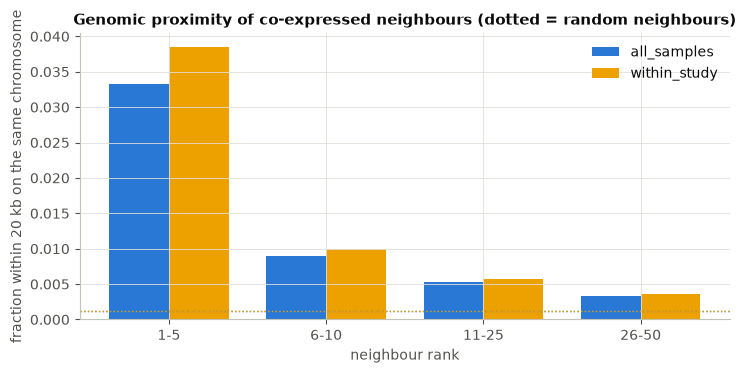

,mode,ranks,near_fraction,random_neighbours
0,all_samples,1-5,0.0333,0.0011
1,all_samples,6-10,0.0090,0.0011
2,all_samples,11-25,0.0053,0.0011
3,all_samples,26-50,0.0034,0.0011
4,within_study,1-5,0.0386,0.0013
5,within_study,6-10,0.0099,0.0013
6,within_study,11-25,0.0057,0.0013
7,within_study,26-50,0.0036,0.0013


In [20]:
coords = genes_tbl[["chromosome", "start", "end"]].copy()
coords["mid"] = (coords["start"] + coords["end"]) / 2
PROX_BP = 20_000


def near_fraction(pairs, a="gene_id", b="neighbour_id"):
    ca, cb = coords.reindex(pairs[a]), coords.reindex(pairs[b])
    same = (ca["chromosome"].to_numpy() == cb["chromosome"].to_numpy())
    near = same & (np.abs(ca["mid"].to_numpy() - cb["mid"].to_numpy()) <= PROX_BP)
    return near.mean()


rng = np.random.default_rng(0)
rank_bins = [(1, 5), (6, 10), (11, 25), (26, PARAMS.top_n)]
prox_rows = []
for m in nb:
    all_genes = result.modes[m].prepared.genes.to_numpy()
    shuffled = nb[m].assign(neighbour_id=rng.permutation(nb[m]["neighbour_id"].to_numpy()))
    baseline = near_fraction(shuffled)
    for lo, hi in rank_bins:
        sel = nb[m][(nb[m]["rank"] >= lo) & (nb[m]["rank"] <= hi)]
        prox_rows.append({"mode": m, "ranks": f"{lo}-{hi}", "near_fraction": near_fraction(sel), "random_neighbours": baseline})
prox = pd.DataFrame(prox_rows)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
width = 0.38
for k, m in enumerate(nb):
    d = prox[prox["mode"] == m]
    ax.bar(np.arange(len(d)) + (k - 0.5) * width, d["near_fraction"], width, color=MODE_COLORS[m], label=m)
    ax.axhline(d["random_neighbours"].iloc[0], color=MODE_COLORS[m], lw=1, ls=":")
ax.set_xticks(range(len(rank_bins))); ax.set_xticklabels([f"{lo}-{hi}" for lo, hi in rank_bins])
ax.set_xlabel("neighbour rank"); ax.set_ylabel(f"fraction within {PROX_BP // 1000} kb on the same chromosome")
ax.set_title("Genomic proximity of co-expressed neighbours (dotted = random neighbours)"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "coexpr_proximity.png"); plt.show()
display(prox.round(4))


In [21]:
term_sets = build_term_sets(go, result.modes["all_samples"].prepared.genes, onto, MIN_TERM_SIZE, MAX_TERM_SIZE)
n_genes_net = len(result.modes["all_samples"].prepared.genes)
cal_rows = []
for m in nb:
    real = neighbourhood_enrichment(nb[m], term_sets)
    gene_ids = nb[m]["gene_id"].unique()
    pool = result.modes[m].prepared.genes.to_numpy()
    random_lists = pd.DataFrame({
        "gene_id": np.repeat(gene_ids, PARAMS.top_n),
        "neighbour_id": np.concatenate([rng.choice(pool, PARAMS.top_n, replace=False) for _ in gene_ids]),
    })
    fake = neighbourhood_enrichment(random_lists, term_sets)
    cal_rows.append({
        "mode": m,
        "genes with >=1 term (real neighbours)": real["gene_id"].nunique() / len(gene_ids),
        "genes with >=1 term (random lists)": fake["gene_id"].nunique() / len(gene_ids),
        "median size of the best term (real)": real.sort_values("q_value").groupby("gene_id")["term_size"].first().median() if len(real) else np.nan,
        "median size of the best term (random)": fake.sort_values("q_value").groupby("gene_id")["term_size"].first().median() if len(fake) else np.nan,
    })
calibration = pd.DataFrame(cal_rows).set_index("mode").round(3)
display(calibration)
display(Markdown(
    f"> GO universe: **{term_sets.n_genes:,} annotated genes ({pct(term_sets.n_genes / n_genes_net)} of the network)**, {len(term_sets.terms):,} terms with "
    f"{MIN_TERM_SIZE}-{MAX_TERM_SIZE} genes; {term_sets.source}."
))


,genes with >=1 term (real neighbours),genes with >=1 term (random lists),median size of the best term (real),median size of the best term (random)
mode,,,,
all_samples,0.548,0.01,138.0,15.5
within_study,0.569,0.01,130.0,26.0


> GO universe: **6,650 annotated genes (66% of the network)**, 3,543 terms with 5-500 genes; GO annotations propagated over is_a/part_of with go-basic.obo.

In [22]:
parts = []
for m in nb:
    d = prox[prox["mode"] == m]
    parts.append(f"`{m}`: {pct(d.iloc[0]['near_fraction'], 1)} of the top-5 neighbours lie within {PROX_BP // 1000} kb "
                 f"(ranks {d.iloc[-1]['ranks']}: {pct(d.iloc[-1]['near_fraction'], 1)}; random neighbours: {pct(d.iloc[0]['random_neighbours'], 2)})")
cal = "; ".join(
    f"`{m}`: {pct(calibration.loc[m, 'genes with >=1 term (real neighbours)'])} of genes show an enriched term with their real neighbours versus "
    f"{pct(calibration.loc[m, 'genes with >=1 term (random lists)'], 1)} with random lists of the same size" for m in nb)
display(Markdown("**Answer.** (8a) " + "; ".join(parts) + ". (8b) " + cal + "."))


**Answer.** (8a) `all_samples`: 3.3% of the top-5 neighbours lie within 20 kb (ranks 26-50: 0.3%; random neighbours: 0.11%); `within_study`: 3.9% of the top-5 neighbours lie within 20 kb (ranks 26-50: 0.4%; random neighbours: 0.13%). (8b) `all_samples`: 55% of genes show an enriched term with their real neighbours versus 1.0% with random lists of the same size; `within_study`: 57% of genes show an enriched term with their real neighbours versus 1.0% with random lists of the same size.

In [23]:
fold = {m: prox[(prox["mode"] == m)].iloc[0]["near_fraction"] / prox[(prox["mode"] == m)].iloc[0]["random_neighbours"] for m in nb}
deep_fold = {m: prox[(prox["mode"] == m)].iloc[-1]["near_fraction"] / prox[(prox["mode"] == m)].iloc[-1]["random_neighbours"] for m in nb}
fp = max(calibration["genes with >=1 term (random lists)"])
tp = min(calibration["genes with >=1 term (real neighbours)"])
go_note = (
    "GO annotations are propagated to ancestors with go-basic.obo and terms carry names, so the hits are readable."
    if onto is not None else
    "With direct GO annotations only (no propagation, no term names) the signal is real but unreadable to a human; the Gene Ontology file would fix that."
)
size_real = [calibration.loc[m, "median size of the best term (real)"] for m in nb]
size_rand = [calibration.loc[m, "median size of the best term (random)"] for m in nb]
display(Markdown(
    "**Conclusion.** (8a) The best neighbours are physically close far more often than random ones "
    f"({', '.join(f'{m}: {fold[m]:.0f}x' for m in nb)} at ranks 1-5, still {', '.join(f'{deep_fold[m]:.1f}x' for m in nb)} at the deepest ranks), "
    "and the effect fades with rank. That supports structured co-regulation beyond annotation (clusters, shared promoters) — with the read-crosstalk caveat above — "
    "but in absolute terms only a few percent of top neighbours are adjacent, so most co-expression links are between distant genes. "
    f"(8b) The enrichment procedure is conservative: random lists give a term in {pct(fp, 1)} of genes against {pct(tp)} for real neighbourhoods, "
    f"and the terms found by chance are small (median size {'/'.join(f'{v:.0f}' for v in size_rand)} genes) whereas the best term of a real neighbourhood is larger "
    f"({'/'.join(f'{v:.0f}' for v in size_real)} genes). {go_note} "
    f"{pct(1 - term_sets.n_genes / n_genes_net)} of the network genes have no GO term inside the {MIN_TERM_SIZE}-{MAX_TERM_SIZE}-gene window and cannot contribute."
))


**Conclusion.** (8a) The best neighbours are physically close far more often than random ones (all_samples: 29x, within_study: 31x at ranks 1-5, still 2.9x, 2.8x at the deepest ranks), and the effect fades with rank. That supports structured co-regulation beyond annotation (clusters, shared promoters) — with the read-crosstalk caveat above — but in absolute terms only a few percent of top neighbours are adjacent, so most co-expression links are between distant genes. (8b) The enrichment procedure is conservative: random lists give a term in 1.0% of genes against 55% for real neighbourhoods, and the terms found by chance are small (median size 16/26 genes) whereas the best term of a real neighbourhood is larger (138/130 genes). GO annotations are propagated to ancestors with go-basic.obo and terms carry names, so the hits are readable. 34% of the network genes have no GO term inside the 5-500-gene window and cannot contribute.

## 9. From neighbour lists to a network (preview of the web view)

**Question.** Which edge cut-off gives a network that can be read — and does it have modular structure that
matches function?

*Edges.* `select_edges` turns the directed lists into undirected edges: a pair counts once if its **mutual
rank** is at most a cut-off (and, optionally, its within-study support is at least `SUPPORT_MIN`). Mutual rank is
the knob because it starts at 1 (each other's best neighbour) and grows smoothly. The risk of a loose cut-off is
**percolation**: past some value the graph merges into one giant component and stops being interpretable, so
the first step is a sweep.


,mode,mutual rank <=,edges,genes with an edge,components >= 5 genes,largest component,largest / genes with an edge
0,all_samples,1,1129,2258,0,2,0.001
1,all_samples,2,3617,5050,252,30,0.006
2,all_samples,3,6233,6609,162,2837,0.429
3,all_samples,5,12232,8257,25,7462,0.904
4,all_samples,10,28096,9506,2,9391,0.988
5,within_study,1,1207,2414,0,2,0.001
6,within_study,2,3850,5304,267,31,0.006
7,within_study,3,6568,6806,162,3260,0.479
8,within_study,5,12809,8351,17,7674,0.919
9,within_study,10,29750,9498,2,9400,0.990


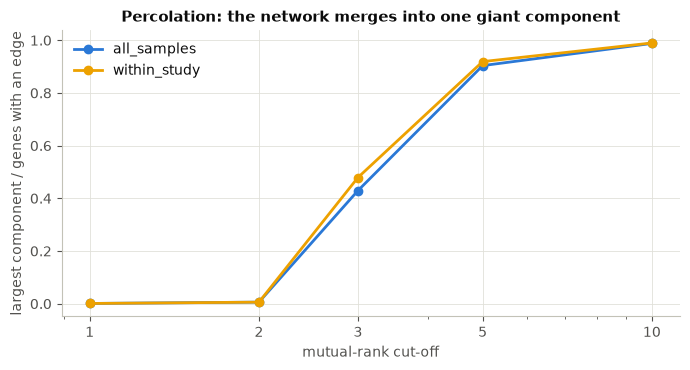

In [24]:
def graph_of(m, edges):
    genes = result.modes[m].prepared.genes
    pos = {g: i for i, g in enumerate(genes)}
    ia, ib = edges["a"].map(pos).to_numpy(), edges["b"].map(pos).to_numpy()
    adj = sparse.coo_matrix((np.ones(len(edges)), (ia, ib)), shape=(len(genes), len(genes))).tocsr()
    adj = ((adj + adj.T) > 0).astype(np.int8)
    n_comp, labels = connected_components(adj, directed=False)
    return adj, labels, np.bincount(labels), np.asarray(adj.sum(axis=1)).ravel()


SWEEP = (1, 2, 3, 5, 10)
sweep_rows = []
for m in nb:
    for mr in SWEEP:
        edges = select_edges(nb[m], mr, SUPPORT_MIN if m == "all_samples" else None)
        _, _, sizes, degree = graph_of(m, edges)
        with_edge = int((degree > 0).sum())
        sweep_rows.append({
            "mode": m, "mutual rank <=": mr, "edges": len(edges), "genes with an edge": with_edge,
            "components >= 5 genes": int((sizes >= 5).sum()), "largest component": int(sizes.max()),
            "largest / genes with an edge": sizes.max() / with_edge if with_edge else np.nan,
        })
sweep = pd.DataFrame(sweep_rows)
display(sweep.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
for m in nb:
    d = sweep[sweep["mode"] == m]
    ax.plot(d["mutual rank <="], d["largest / genes with an edge"], marker="o", color=MODE_COLORS[m], lw=2, label=m)
ax.set_xscale("log"); ax.set_xticks(SWEEP); ax.set_xticklabels(SWEEP)
ax.set_xlabel("mutual-rank cut-off"); ax.set_ylabel("largest component / genes with an edge")
ax.set_title("Percolation: the network merges into one giant component"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "coexpr_percolation.png"); plt.show()


In [25]:
perc = {}
for m in nb:
    d = sweep[sweep["mode"] == m].sort_values("mutual rank <=")
    big = d[d["largest / genes with an edge"] > 0.25]
    perc[m] = int(big["mutual rank <="].iloc[0]) if len(big) else None
at_cut = sweep[sweep["mutual rank <="] == MR_CUT].set_index("mode")
display(Markdown(
    "**Answer.** The graph stays modular up to a very small cut-off and then merges: "
    + "; ".join(
        f"`{m}`: the largest component holds {pct(at_cut.loc[m, 'largest / genes with an edge'])} of the genes with an edge at mutual rank <= {MR_CUT} "
        f"({int(at_cut.loc[m, 'components >= 5 genes'])} components of >= 5 genes, {int(at_cut.loc[m, 'edges']):,} edges over {int(at_cut.loc[m, 'genes with an edge']):,} genes)"
        + (f"; yet a single component already holds more than a quarter of the genes with an edge at mutual rank <= {perc[m]} "
           f"({pct(sweep[(sweep['mode'] == m) & (sweep['mutual rank <='] == perc[m])]['largest / genes with an edge'].iloc[0])})" if perc[m] else "") for m in nb)
    + "."
))


**Answer.** The graph stays modular up to a very small cut-off and then merges: `all_samples`: the largest component holds 1% of the genes with an edge at mutual rank <= 2 (252 components of >= 5 genes, 3,617 edges over 5,050 genes); yet a single component already holds more than a quarter of the genes with an edge at mutual rank <= 3 (43%); `within_study`: the largest component holds 1% of the genes with an edge at mutual rank <= 2 (267 components of >= 5 genes, 3,850 edges over 5,304 genes); yet a single component already holds more than a quarter of the genes with an edge at mutual rank <= 3 (48%).

In [26]:
edge_sets = {m: select_edges(nb[m], MR_CUT, SUPPORT_MIN if m == "all_samples" else None) for m in nb}
graphs = {m: graph_of(m, edge_sets[m]) for m in nb}


def component_table(m, n_top=8):
    adj, labels, sizes, degree = graphs[m]
    genes = result.modes[m].prepared.genes
    rows = []
    for comp in np.argsort(sizes)[::-1][:n_top]:
        members = list(genes[labels == comp])
        if len(members) < 3:
            continue
        enr = enrich_gene_set(members, term_sets)
        top = enr.iloc[0] if len(enr) else None
        rows.append({
            "genes": len(members),
            "best GO term": (top["term"] if top is not None and top["name"] == top["term"] else f"{top['term']} {top['name']}") if top is not None else "-",
            "overlap": int(top["overlap"]) if top is not None else 0,
            "term size": int(top["term_size"]) if top is not None else 0,
            "q": top["q_value"] if top is not None else np.nan,
            "e.g.": "; ".join(genes_tbl["description"].reindex(members[:2]).fillna("").str.slice(0, 40)),
        })
    return pd.DataFrame(rows)


components_enriched = {}
for m in nb:
    adj, labels, sizes, degree = graphs[m]
    genes = result.modes[m].prepared.genes
    big = [c for c in np.argsort(sizes)[::-1] if sizes[c] >= 5]
    hits = sum(len(enrich_gene_set(list(genes[labels == c]), term_sets)) > 0 for c in big)
    components_enriched[m] = (hits, len(big))
    print(f"\n=== largest components at mutual rank <= {MR_CUT}, {m} ({hits} of {len(big)} components of >= 5 genes have a significant GO term) ===")
    print(component_table(m).to_string(index=False, float_format=lambda v: f"{v:.1e}"))



=== largest components at mutual rank <= 2, all_samples (86 of 252 components of >= 5 genes have a significant GO term) ===
 genes                                         best GO term  overlap  term size       q                                                                               e.g.
    30                                                    -        0          0     NaN Has domain(s) with predicted UDP-N-acety; Ortholog(s) have extracellular region lo
    28                     GO:0005783 endoplasmic reticulum        8        326 1.9e-02 Ortholog(s) have GPI-anchor transamidase; Ortholog(s) have protein serine/threonin
    23                                                    -        0          0     NaN Has domain(s) with predicted ubiquitin-p; Ortholog of A. nidulans FGSC A4 : AN4945
    17                                                    -        0          0     NaN Ortholog(s) have role in production of s; Has domain(s) with predicted zinc ion bi
    17              


=== largest components at mutual rank <= 2, within_study (91 of 267 components of >= 5 genes have a significant GO term) ===


 genes                                                                                                     best GO term  overlap  term size       q                                                                               e.g.
    31                                                                                   GO:0042254 ribosome biogenesis       26        230 1.1e-31 Ortholog(s) have cytosol, nucleus locali; Ortholog(s) have snoRNA binding activity
    25                                                                                    GO:0022402 cell cycle process       16        386 7.3e-12 Ortholog(s) have role in attachment of t; Ortholog(s) have GTP binding, GTPase act
    24                                                                                                                -        0          0     NaN    Ortholog(s) have nucleus localization; Ortholog of A. nidulans FGSC A4 : AN2897
    21 GO:0016705 oxidoreductase activity, acting on paired donors, with inc

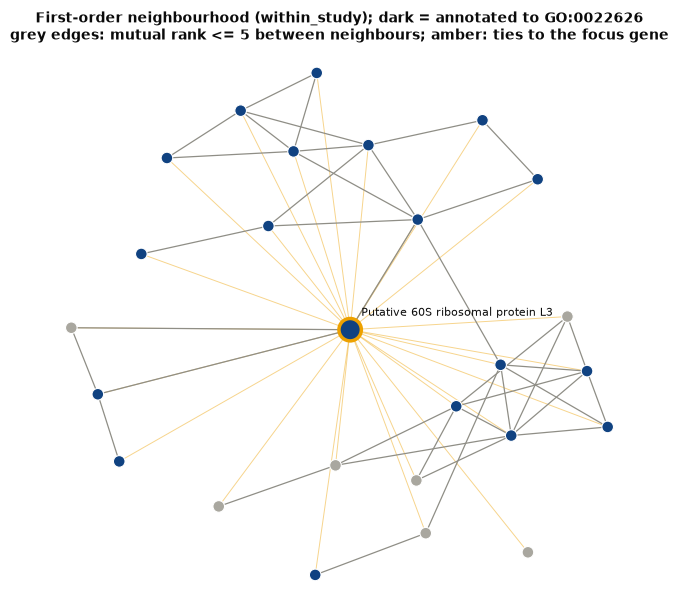

In [27]:
# First-order neighbourhood of the ribosomal protein (the AFED-style "subnetwork of a gene"): the gene, its 25 best
# within-study neighbours, and the edges among them when each is in the other's top list.
def spring_layout(adj, iters=300, seed=0):
    n = adj.shape[0]
    rng_ = np.random.default_rng(seed)
    pos_ = rng_.random((n, 2))
    k = 1.0 / np.sqrt(n)
    for it in range(iters):
        t = 0.1 * (1 - it / iters)
        delta = pos_[:, None, :] - pos_[None, :, :]
        dist = np.linalg.norm(delta, axis=-1) + 1e-9
        disp = ((k * k / dist ** 2)[..., None] * delta).sum(axis=1) - ((adj * dist / k)[..., None] * delta).sum(axis=1)
        length = np.linalg.norm(disp, axis=1, keepdims=True) + 1e-9
        pos_ += disp / length * np.minimum(length, t)
    return pos_


focus_mode = "within_study" if "within_study" in nb else next(iter(nb))
focus = present.get("60S ribosomal protein L3") or next(iter(present.values()), None)
if focus is not None:
    lst = nb[focus_mode]
    first = lst[(lst["gene_id"] == focus) & (lst["rank"] <= 25)]["neighbour_id"].tolist()
    members = [focus] + first
    SUB_MR = 5                                           # edges among the neighbours: mutual rank <= this (all of them would be a near-complete clique)
    sub = lst[lst["gene_id"].isin(members) & lst["neighbour_id"].isin(members) & (lst["mutual_rank"] <= SUB_MR)]
    idx = {g: i for i, g in enumerate(members)}
    adj_f = np.zeros((len(members), len(members)))
    for a_, b_ in zip(sub["gene_id"], sub["neighbour_id"]):
        adj_f[idx[a_], idx[b_]] = adj_f[idx[b_], idx[a_]] = 1
    links = [idx[g] for g in first]                      # every first-order neighbour is tied to the focus gene by construction
    adj_layout = adj_f.copy()
    adj_layout[0, links] = adj_layout[links, 0] = 1
    xy = spring_layout(adj_layout)
    top_term = enrich_gene_set(members, term_sets)
    term_id = top_term.iloc[0]["term"] if len(top_term) else None
    member_set = set(term_sets.genes[term_sets.matrix[:, term_sets.terms.get_loc(term_id)].nonzero()[0]]) if term_id else set()
    fig, ax = plt.subplots(figsize=(6.2, 6.2))
    ax.grid(False); ax.axis("off")
    for j in links:
        ax.plot(xy[[0, j], 0], xy[[0, j], 1], color="#eda100", lw=0.7, alpha=0.45, zorder=1)
    for i, j in zip(*np.triu_indices(len(members), 1)):
        if adj_f[i, j]:
            ax.plot(xy[[i, j], 0], xy[[i, j], 1], color="#8f8e86", lw=0.9, zorder=1)
    colors = ["#104281" if g in member_set else "#a9a79f" for g in members]
    ax.scatter(xy[:, 0], xy[:, 1], s=[260 if g == focus else 70 for g in members], c=colors, edgecolors=["#eda100" if g == focus else "white" for g in members], linewidths=[2.5 if g == focus else 0.8 for g in members], zorder=2)
    ax.annotate(genes_tbl.loc[focus, "description"][:34], xy[0], xytext=(8, 10), textcoords="offset points", fontsize=8, color=INK)
    ax.set_title(f"First-order neighbourhood ({focus_mode}); dark = annotated to {term_id or 'n/a'}\ngrey edges: mutual rank <= {SUB_MR} between neighbours; amber: ties to the focus gene", fontsize=10)
    fig.tight_layout(); save_fig(fig, "coexpr_subnetwork.png"); plt.show()


In [28]:
parts = [f"`{m}`: {components_enriched[m][0]} of {components_enriched[m][1]} components of >= 5 genes carry a significant GO term" for m in nb]
display(Markdown(
    f"**Conclusion.** The cut-off is the whole story: at mutual rank <= {MR_CUT} the network is a set of small modules ({'; '.join(parts)}), "
    "while loosening it by a few units merges almost everything into one component (table and figure above), so a fixed loose cut-off would show a "
    "hairball. The web view should therefore start strict and expose mutual rank as a slider, with within-study support as a second filter. "
    "Connected components are the coarsest module definition (one bridging edge merges two modules); a community-detection layer on top of these same "
    "columns is the natural next step, and modules without a GO term are not errors — many genes are unannotated or have no coherent function class."
))


**Conclusion.** The cut-off is the whole story: at mutual rank <= 2 the network is a set of small modules (`all_samples`: 86 of 252 components of >= 5 genes carry a significant GO term; `within_study`: 91 of 267 components of >= 5 genes carry a significant GO term), while loosening it by a few units merges almost everything into one component (table and figure above), so a fixed loose cut-off would show a hairball. The web view should therefore start strict and expose mutual rank as a slider, with within-study support as a second filter. Connected components are the coarsest module definition (one bridging edge merges two modules); a community-detection layer on top of these same columns is the natural next step, and modules without a GO term are not errors — many genes are unannotated or have no coherent function class.

## 10. Reproducibility: this notebook = `atlas coexpr build`

**Question.** Does a fresh run of the library pipeline reproduce what this notebook analysed, and — if
`atlas coexpr build` has been run with the same parameters — what it wrote to disk?


In [29]:
fresh = build_coexpression(con, PARAMS, gaf_path=FUNGIDB_GO_GAF_FILE, obo_path=GO_OBO_FILE)
pd.testing.assert_frame_equal(fresh.neighbours(), result.neighbours())
msg = "A fresh `build_coexpression` run reproduces this notebook's neighbour tables exactly (deterministic)."
if COEXPRESSION_NEIGHBOURS_FILE.is_file():
    on_disk = pd.read_parquet(COEXPRESSION_NEIGHBOURS_FILE)
    if len(on_disk) == len(fresh.neighbours()) and set(on_disk["gene_id"]) == set(fresh.neighbours()["gene_id"]):
        pd.testing.assert_frame_equal(on_disk.reset_index(drop=True), fresh.neighbours().reset_index(drop=True), check_dtype=False)
        msg += f" It also matches `{COEXPRESSION_NEIGHBOURS_FILE.name}` written by the command."
    else:
        msg += (f" `{COEXPRESSION_NEIGHBOURS_FILE.name}` on disk was produced with different data or parameters "
                f"({len(on_disk):,} rows vs {len(fresh.neighbours()):,}); run `atlas coexpr build` to refresh it.")
else:
    msg += " No output on disk yet: run `atlas coexpr build` (or `atlas refresh`)."
display(Markdown(f"**Consistency check passed.** {msg} Edges carry {len(fresh.neighbours().columns)} columns."))


**Consistency check passed.** A fresh `build_coexpression` run reproduces this notebook's neighbour tables exactly (deterministic). It also matches `coexpression_neighbours.parquet` written by the command. Edges carry 10 columns.

**Conclusion.** The notebook adds no logic of its own to the network: the neighbour lists, edge-support columns,
benchmark and enrichment all come from `aoryzae_atlas.coexpr`. When a study is added, `atlas refresh` rebuilds the
tables and this notebook can be re-executed top to bottom to re-read every number above.


## 11. Limitations and next steps

- **TPM is compositional.** A few extremely abundant genes (amylases in induced samples) shift every other gene's
  TPM; correlations among moderately expressed genes can partly reflect that. A size-factor-based normalisation on
  counts (AFED used upper-quartile) is a possible robustness check, not done here.
- **Study/strain are only partly separable.** `within_study` centering removes between-study offsets but also real
  between-study biology; there is no strain-level correction beyond that, and studies with fewer than
  `min_samples_per_study` biosamples do not enter that mode.
- **GO coverage.** Enrichment uses the FungiDB GAF. With `database/GeneOntology/go-basic.obo` present, annotations are
  propagated to ancestors (is_a / part_of) and terms are named; without it only direct annotations and bare GO ids are used
  (Section 8 prints which). Terms are limited to 5-500 genes, which drops broad terms and leaves some genes with no usable
  term; that share of the network carries no enrichment signal. Propagation makes terms of one lineage non-independent, so
  several significant terms for one gene often describe the same thing.
- **Benchmark groups are crude** (seven GO/keyword sets, no confidence interval); read AUC differences below a few
  hundredths as ties.
- **Edges are statistical relationships**, not regulatory interactions; the within-study median and mutual rank say
  how robust a relationship is, not what causes it.
- **Next:** export the edge table to the web app as a network view (mutual-rank and support sliders, mode switch,
  gene-set query, enrichment panel), and a community-detection layer for modules.
